# 02. Wyniki zadań Spark: analiza statystyczna i modele MLlib

Notatnik wizualizuje pliki zapisane przez zadania Spark:

| Plik | Zadanie Spark |
|---|---|
| `reports/analysis.json` | `src/mushroom/analysis.py` (χ², FP-Growth) |
| `reports/metrics.json` | `src/mushroom/train.py` (porównanie i strojenie modeli) |

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP = ROOT / "reports"
FIG = REP / "figures"
load = lambda n: json.loads((REP / n).read_text(encoding="utf-8"))
analysis, metrics = load("analysis.json"), load("metrics.json")

def save(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. Analiza statystyczna w Spark

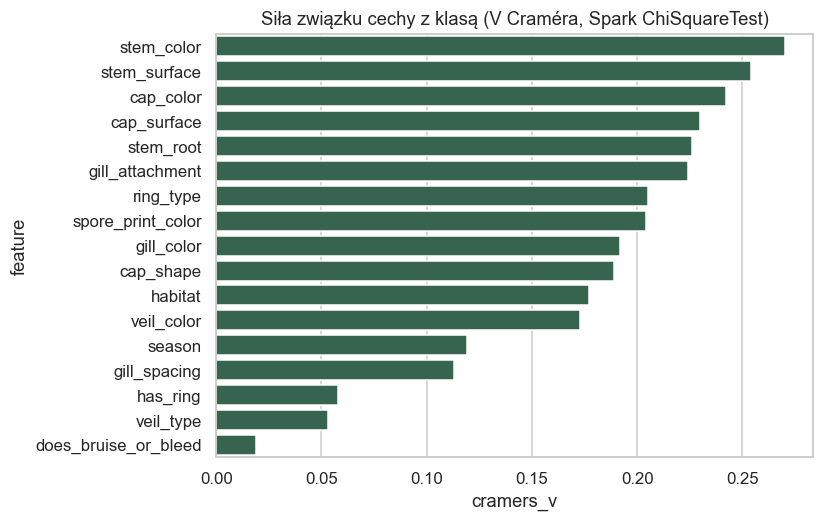

,feature,chi2,p_value,cramers_v
0,stem_color,4439.1,0.000000,0.270
1,stem_surface,3928.3,0.000000,0.254
2,cap_color,3576.0,0.000000,0.242
3,cap_surface,3227.0,0.000000,0.230
4,stem_root,3102.5,0.000000,0.226
5,gill_attachment,3068.8,0.000000,0.224
6,ring_type,2557.1,0.000000,0.205
7,spore_print_color,2536.7,0.000000,0.204
8,gill_color,2240.0,0.000000,0.192
9,cap_shape,2175.2,0.000000,0.189


In [2]:
chi = pd.DataFrame(analysis["chi_square"])
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=chi, y="feature", x="cramers_v", color="#2f6b4f", ax=ax)
ax.set_title("Siła związku cechy z klasą (V Craméra, Spark ChiSquareTest)")
save("06_cramers_v")
plt.show()
chi

### Reguły asocjacyjne FP-Growth

Każdy rekord to koszyk elementów `cecha=wartość` oraz `class=p|e`. Pokazujemy reguły, których następnikiem jest klasa (pomijamy reguły, które tylko dokładają warunki do reguły już pokazanej).

In [3]:
for cls, name in [("p", "trujący"), ("e", "jadalny")]:
    t = pd.DataFrame(analysis["association_rules"][cls])
    t["antecedent"] = t["antecedent"].apply(" ∧ ".join)
    print(f"Reguły → {name}")
    display(t)

Reguły → trujący


,antecedent,confidence,support,lift
0,ring_type=z,1.000,0.035,1.806
1,gill_spacing=c ∧ stem_color=y,1.000,0.037,1.806
2,cap_shape=b ∧ has_ring=t,1.000,0.030,1.806
3,cap_surface=t ∧ does_bruise_or_bleed=f ∧ gill_...,1.000,0.046,1.806
4,cap_surface=t ∧ gill_spacing=c ∧ has_ring=t,1.000,0.034,1.806
5,cap_color=n ∧ cap_surface=t ∧ gill_spacing=c,1.000,0.031,1.806
6,cap_shape=x ∧ cap_surface=g ∧ does_bruise_or_b...,0.949,0.035,1.714
7,does_bruise_or_bleed=f ∧ has_ring=t ∧ stem_sur...,0.937,0.041,1.691
8,cap_surface=k,0.921,0.035,1.664
9,cap_shape=b ∧ gill_spacing=missing,0.920,0.035,1.660


Reguły → jadalny


,antecedent,confidence,support,lift
0,cap_color=n ∧ gill_attachment=e ∧ veil_color=m...,0.963,0.032,2.158
1,cap_color=n ∧ gill_attachment=e ∧ veil_type=mi...,0.963,0.032,2.158
2,gill_color=w ∧ stem_root=missing ∧ stem_surface=s,0.939,0.030,2.105


## 2. Porównanie modeli MLlib

In [4]:
rnd = pd.DataFrame(metrics["random"]).set_index("model")
sp = pd.DataFrame(metrics["species_holdout"]).set_index("model")
cmp = pd.DataFrame({
    "acc_losowy": rnd.accuracy, "auc_losowy": rnd.auc,
    "acc_gatunki": sp.accuracy, "auc_gatunki": sp.auc,
    "czułość_gatunki": sp.recall_poisonous, "trujące→jadalne_gatunki": sp.poisonous_as_edible,
})
print(metrics["data"])
cmp

{'rows': 60923, 'random_split': [48943, 11980], 'species_split': [137, 36], 'species_split_rows': [48215, 12708]}


,acc_losowy,auc_losowy,acc_gatunki,auc_gatunki,czułość_gatunki,trujące→jadalne_gatunki
model,,,,,,
LogisticRegression,0.8609,0.9374,0.5548,0.5995,0.6130,2732
DecisionTree,0.8846,0.9688,0.4514,0.4248,0.5292,3324
RandomForest,0.9891,0.9996,0.5945,0.6090,0.7422,1820
GBT,0.9910,0.9998,0.5195,0.5190,0.5882,2907


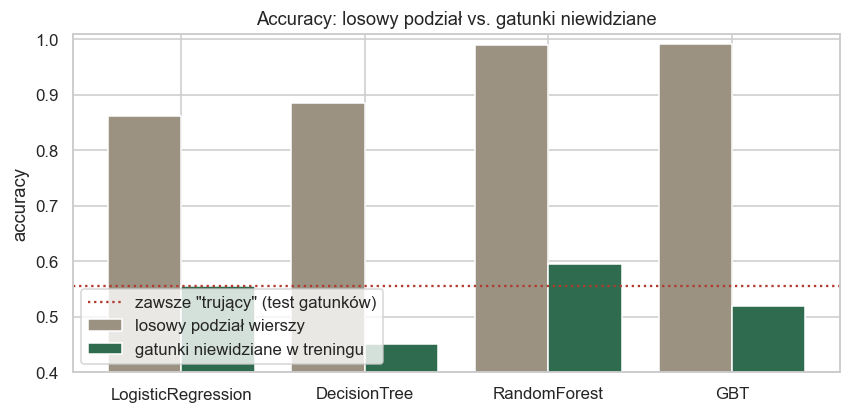

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cmp))
ax.bar(x - 0.2, cmp.acc_losowy, 0.4, label="losowy podział wierszy", color="#9b9282")
ax.bar(x + 0.2, cmp.acc_gatunki, 0.4, label="gatunki niewidziane w treningu", color="#2f6b4f")
ax.axhline(0.556, color="#b03a2e", ls=":", label="zawsze \"trujący\" (test gatunków)")
ax.set_xticks(x, cmp.index); ax.set_ylim(0.4, 1.01); ax.set_ylabel("accuracy")
ax.legend(loc="lower left"); ax.set_title("Accuracy: losowy podział vs. gatunki niewidziane")
save("07_model_comparison")
plt.show()

### Strojenie lasu losowego (CrossValidator z foldami po gatunkach)

Każdy gatunek trafia w całości do jednego z 4 foldów, więc walidacja mierzy jakość dla gatunków nieznanych.

In [6]:
pd.DataFrame(metrics["tuning"])

,numTrees,maxDepth,cv_auc
0,50,8,0.6576
1,50,12,0.6619
2,100,8,0.6788
3,100,12,0.6813


Wszystkie punkty siatki mają CV AUC 0,66-0,68, więc zmiana hiperparametrów prawie nic nie daje na nowych gatunkach. Najlepsze ustawienie (100 drzew, głębokość 12) to to samo, którego używamy w porównaniu i w strumieniu.

## 3. Próg bezpieczeństwa

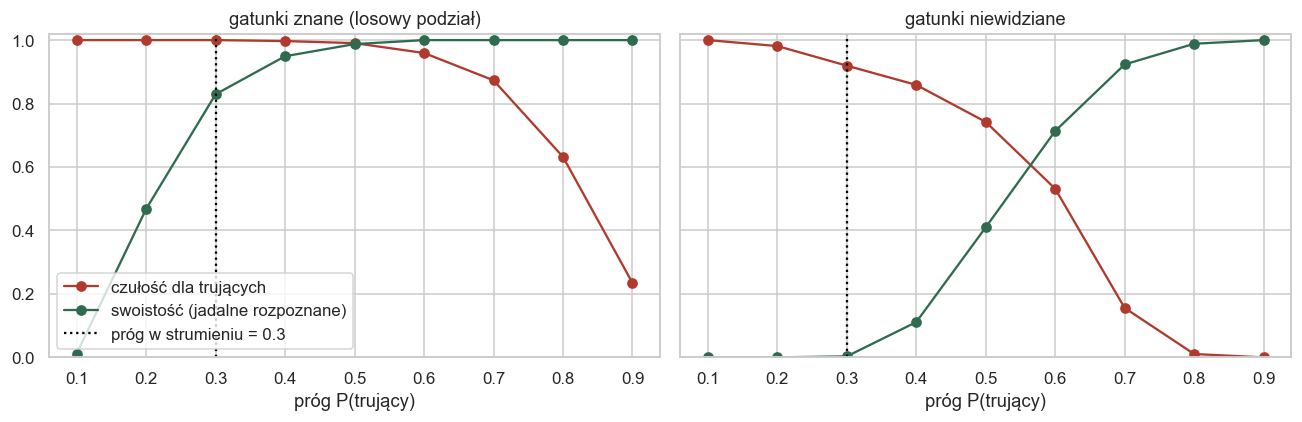

known                                                    unseen  \
          accuracy recall_poisonous specificity poisonous_as_edible accuracy   
threshold                                                                      
0.1         0.5567           1.0000      0.0121                   0   0.5556   
0.2         0.7612           1.0000      0.4678                   0   0.5452   
0.3         0.9235           1.0000      0.8294                   0   0.5123   
0.4         0.9755           0.9970      0.9492                  20   0.5265   
0.5         0.9891           0.9905      0.9875                  63   0.5945   
0.6         0.9776           0.9594      1.0000                 268   0.6124   
0.7         0.9301           0.8733      1.0000                 837   0.4969   
0.8         0.7972           0.6320      1.0000                2430   0.4452   
0.9         0.5781           0.2347      1.0000                5054   0.4444   

                                                            
          recall_poisonous specificity poisonous_as_edible  
threshold                                                   
0.1                 1.0000      0.0000                   0  
0.2                 0.9813      0.0000                 132  
0.3                 0.9195      0.0032                 568  
0.4                 0.8588      0.1112                 997  
0.5                 0.7422      0.4099                1820  
0.6                 0.5316      0.7135                3307  
0.7                 0.1558      0.9233                5960  
0.8                 0.0106      0.9885                6985  
0.9                 0.0000      1.0000                7060

In [7]:
thr = metrics["model"]["threshold"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (key, title) in zip(axes, [("known", "gatunki znane (losowy podział)"), ("unseen", "gatunki niewidziane")]):
    c = pd.DataFrame(metrics["threshold_curve"][key])
    ax.plot(c.threshold, c.recall_poisonous, marker="o", color="#b03a2e", label="czułość dla trujących")
    ax.plot(c.threshold, c.specificity, marker="o", color="#2f6b4f", label="swoistość (jadalne rozpoznane)")
    ax.axvline(thr, color="black", ls=":", label=f"próg w strumieniu = {thr}")
    ax.set_xlabel("próg P(trujący)"); ax.set_ylim(0, 1.02); ax.set_title(title)
axes[0].legend(loc="lower left")
plt.tight_layout()
save("08_threshold")
plt.show()
pd.concat({k: pd.DataFrame(v).set_index("threshold") for k, v in metrics["threshold_curve"].items()}, axis=1)